Dataset shape: (8500, 18)


,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0.0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92.0,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45.0,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97.0,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0.0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt


user_id                      0
age                          0
gender                       0
occupation_type              0
chronotype                   0
bedtime_phone_minutes        0
primary_bedtime_app         26
screen_brightness_pct        0
blue_light_filter_active     0
caffeine_post_5pm_mg        21
physical_activity_min        0
sleep_latency_min           22
total_sleep_hours            0
deep_sleep_pct               0
rem_sleep_pct                0
morning_alarm_snoozes        0
next_day_fatigue_score       0
sleep_debt_category          0
dtype: int64
Duplicates: 0
Original class balance:
sleep_debt_category
Moderate Debt        4462
Mild Deficit         2004
Optimal Recovery     1387
Severe Sleep Debt     647
Name: count, dtype: int64
Binary class balance:
severe_sleep_debt
0    7853
1     647
Name: count, dtype: int64


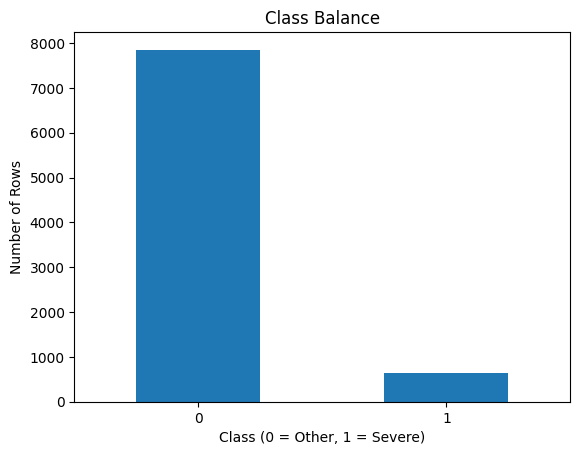

Training rows: 6800
Testing rows: 1700
Severe cases in training: 518
Severe cases in testing: 129


In [1]:
# Load the dataset
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/bedtime_screentime_sleep_debt.csv")

# Check the dataset
print("Dataset shape:", df.shape)
display(df.head())

# Check missing values
print(df.isnull().sum())

# Check duplicate rows
print("Duplicates:", df.duplicated().sum())

# Remove duplicates and rows with missing target
df = df.drop_duplicates()
df = df.dropna(subset=["sleep_debt_category"])

# Remove ID and columns that may cause data leakage
df = df.drop(columns=[
    "user_id",
    "total_sleep_hours",
    "sleep_latency_min",
    "deep_sleep_pct",
    "next_day_fatigue_score"
])

# Check original class balance
print("Original class balance:")
print(df["sleep_debt_category"].value_counts())

# Convert target into binary values
df["severe_sleep_debt"] = (
    df["sleep_debt_category"] == "Severe Sleep Debt"
).astype(int)

# Remove the original target column
df = df.drop(columns=["sleep_debt_category"])

# Check new class balance
print("Binary class balance:")
print(df["severe_sleep_debt"].value_counts())

# Show class balance in a bar chart
df["severe_sleep_debt"].value_counts().sort_index().plot(
    kind="bar",
    rot=0
)

plt.title("Class Balance")
plt.xlabel("Class (0 = Other, 1 = Severe)")
plt.ylabel("Number of Rows")
plt.show()

# Separate features and target
X = df.drop(columns=["severe_sleep_debt"])
y = df["severe_sleep_debt"]

# Split data into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Check the split
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Severe cases in training:", y_train.sum())
print("Severe cases in testing:", y_test.sum())

In [5]:
# Required libraries
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, confusion_matrix

# Identify numerical and categorical columns
num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns
cat_cols = X_train.select_dtypes(include=["object", "bool"]).columns

# Prepare numerical columns
num_process = SimpleImputer(strategy="median")

# Prepare categorical columns
cat_process = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("num", num_process, num_cols),
    ("cat", cat_process, cat_cols)
])

# Create baseline models
dummy = DummyClassifier(strategy="most_frequent")

rf = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

# Set up cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Get predictions using cross-validation
dummy_pred = cross_val_predict(dummy, X_train, y_train, cv=cv)

rf_pred = cross_val_predict(rf, X_train, y_train, cv=cv)

# Evaluate Dummy Classifier
print("Dummy Classifier Results")
print(classification_report(y_train, dummy_pred, zero_division=0))

# Evaluate Random Forest
print("Random Forest Results")
print(classification_report(y_train, rf_pred, zero_division=0))

# Show Random Forest confusion matrix
print("Random Forest Confusion Matrix")
print(confusion_matrix(y_train, rf_pred))
cm = confusion_matrix(y_train, rf_pred)
print("Rare cases missed:", cm[1, 0], "out of", cm[1].sum())

Dummy Classifier Results
              precision    recall  f1-score   support

           0       0.92      1.00      0.96      6282
           1       0.00      0.00      0.00       518

    accuracy                           0.92      6800
   macro avg       0.46      0.50      0.48      6800
weighted avg       0.85      0.92      0.89      6800

Random Forest Results
              precision    recall  f1-score   support

           0       0.97      0.99      0.98      6282
           1       0.83      0.68      0.75       518

    accuracy                           0.96      6800
   macro avg       0.90      0.84      0.86      6800
weighted avg       0.96      0.96      0.96      6800

Random Forest Confusion Matrix
[[6207   75]
 [ 164  354]]
Rare cases missed: 164 out of 518


In [6]:
# Import evaluation metrics
from sklearn.metrics import recall_score, precision_score, f1_score, accuracy_score

# Calculate Random Forest metrics
rf_recall = recall_score(y_train, rf_pred)
rf_precision = precision_score(y_train, rf_pred)
rf_f1 = f1_score(y_train, rf_pred)
rf_accuracy = accuracy_score(y_train, rf_pred)

# Display results
print("Random Forest Baseline Results")
print("Accuracy:", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall:", round(rf_recall, 4))
print("F1 Score:", round(rf_f1, 4))

Random Forest Baseline Results
Accuracy: 0.9649
Precision: 0.8252
Recall: 0.6834
F1 Score: 0.7476


In [ ]:
# Recall is our main evaluation metric because the dataset is imbalanced.
# Means false negatives are worse than false positive.
# Accuracy alone can be misleading when one class has more samples.
# The baseline Random Forest has 68.34% recall for severe sleep debt.
# It correctly identifies 354 out of 518 severe cases.
# It misses 164 severe cases, which need to be reduced.
# Our goal is to improve Recall while maintaining reasonable Precision and F1-score.

In [9]:
# Create a results table
results = X_train.copy()
results["Actual"] = y_train.values
results["Predicted"] = rf_pred

# Find false negatives and false positives
false_negatives = results[
    (results["Actual"] == 1) & (results["Predicted"] == 0)
]

false_positives = results[
    (results["Actual"] == 0) & (results["Predicted"] == 1)
]

# Find correctly identified severe cases
true_positives = results[
    (results["Actual"] == 1) & (results["Predicted"] == 1)
]
true_negatives = results[
    (results["Actual"] == 0) & (results["Predicted"] == 0)
]

# Display error counts
print("False Negatives:", len(false_negatives))
print("False Positives:", len(false_positives))
print("True Positives:", len(true_positives))
print("True Negatives:", len(true_negatives))

# Compare numerical features
num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns

print("\nNumerical Feature Comparison")
print("Missed severe cases:")
display(false_negatives[num_cols].mean().round(2))

print("Correctly identified severe cases:")
display(true_positives[num_cols].mean().round(2))

# Compare categorical features
cat_cols = X_train.select_dtypes(include=["object", "bool"]).columns

for col in cat_cols:
    print("\nFeature:", col)

    print("Missed cases:")
    display(false_negatives[col].value_counts(normalize=True).head(5).round(2))

    print("Correctly identified cases:")
    display(true_positives[col].value_counts(normalize=True).head(5).round(2))

False Negatives: 164
False Positives: 75
True Positives: 354
True Negatives: 6207

Numerical Feature Comparison
Missed severe cases:


,0
age,34.27
bedtime_phone_minutes,104.54
screen_brightness_pct,61.58
blue_light_filter_active,0.34
caffeine_post_5pm_mg,48.26
physical_activity_min,34.82
rem_sleep_pct,18.78
morning_alarm_snoozes,5.02


Correctly identified severe cases:


,0
age,32.78
bedtime_phone_minutes,131.96
screen_brightness_pct,60.47
blue_light_filter_active,0.40
caffeine_post_5pm_mg,52.79
physical_activity_min,34.34
rem_sleep_pct,18.29
morning_alarm_snoozes,6.30



Feature: gender
Missed cases:


,proportion
gender,
Female,0.54
Male,0.44
Non-Binary,0.02


... (10 outputs left out)


Feature: primary_bedtime_app
Missed cases:


,proportion
primary_bedtime_app,
TikTok / Reels,0.36
YouTube,0.20
Instagram / Reddit,0.18
Streaming (Netflix/Hulu),0.13
Messaging / Chat,0.07


Correctly identified cases:


,proportion
primary_bedtime_app,
TikTok / Reels,0.41
YouTube,0.19
Instagram / Reddit,0.18
Messaging / Chat,0.10
Streaming (Netflix/Hulu),0.09


In [ ]:
# False negatives are actual severe cases predicted as non-severe.
# False positives are non-severe cases predicted as severe.
# We compare missed cases with correctly identified severe cases.
# This helps us understand which features may be related to model errors.

In [10]:
# Create a balanced Random Forest model
rf_balanced = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42
    ))
])

# Get cross-validation predictions
balanced_pred = cross_val_predict(
    rf_balanced, X_train, y_train, cv=cv
)

# Evaluate the model
print("Balanced Random Forest Results")
print(classification_report(y_train, balanced_pred, zero_division=0))

Balanced Random Forest Results
              precision    recall  f1-score   support

           0       0.97      0.99      0.98      6282
           1       0.82      0.62      0.70       518

    accuracy                           0.96      6800
   macro avg       0.89      0.80      0.84      6800
weighted avg       0.96      0.96      0.96      6800



In [11]:
# Get cross-validation probabilities
rf_prob = cross_val_predict(
    rf, X_train, y_train, cv=cv, method="predict_proba"
)[:, 1]

# Test different thresholds
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.5, 0.4, 0.3, 0.2, 0.1]

for threshold in thresholds:
    pred = (rf_prob >= threshold).astype(int)

    print("\nThreshold:", threshold)
    print("Precision:", round(precision_score(y_train, pred), 4))
    print("Recall:", round(recall_score(y_train, pred), 4))
    print("F1 Score:", round(f1_score(y_train, pred), 4))


Threshold: 0.5
Precision: 0.8151
Recall: 0.6892
F1 Score: 0.7469

Threshold: 0.4
Precision: 0.7562
Recall: 0.7664
F1 Score: 0.7613

Threshold: 0.3
Precision: 0.6927
Recall: 0.8224
F1 Score: 0.752

Threshold: 0.2
Precision: 0.6219
Recall: 0.9112
F1 Score: 0.7392

Threshold: 0.1
Precision: 0.4687
Recall: 0.9672
F1 Score: 0.6314


In [12]:
# Import resampling tools
from sklearn.utils import resample
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np

# Store predictions
resampled_pred = np.zeros(len(y_train))

# Apply resampling in each fold
for train_idx, val_idx in cv.split(X_train, y_train):

    X_fold = X_train.iloc[train_idx]
    y_fold = y_train.iloc[train_idx]

    X_val = X_train.iloc[val_idx]

    # Separate majority and minority classes
    X_majority = X_fold[y_fold == 0]
    X_minority = X_fold[y_fold == 1]

    # Increase minority samples
    X_minority_up = resample(
        X_minority,
        replace=True,
        n_samples=len(X_majority),
        random_state=42
    )

    # Combine both classes
    X_resampled = pd.concat([X_majority, X_minority_up])

    y_resampled = pd.concat([
        y_fold.loc[X_majority.index],
        y_fold.loc[X_minority_up.index]
    ])

    # Train model on resampled data
    model = clone(rf)
    model.fit(X_resampled, y_resampled)

    # Predict validation fold
    resampled_pred[val_idx] = model.predict(X_val)

# Evaluate resampled model
print("Resampled Random Forest Results")
print("Precision:", round(precision_score(y_train, resampled_pred), 4))
print("Recall:", round(recall_score(y_train, resampled_pred), 4))
print("F1 Score:", round(f1_score(y_train, resampled_pred), 4))

Resampled Random Forest Results
Precision: 0.751
Recall: 0.7394
F1 Score: 0.7451


In [13]:
# Train the baseline model
rf.fit(X_train, y_train)

# Get feature names after preprocessing
feature_names = rf.named_steps["preprocessor"].get_feature_names_out()

# Get feature importance
importances = rf.named_steps["model"].feature_importances_

# Create importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Sort features by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=True
)

display(importance_df.tail(10))

,Feature,Importance
3,num__blue_light_filter_active,0.011691
13,cat__occupation_type_Healthcare / Shift Worker,0.017712
18,cat__chronotype_Night Owl,0.024049
4,num__caffeine_post_5pm_mg,0.041952
0,num__age,0.045833
5,num__physical_activity_min,0.048414
6,num__rem_sleep_pct,0.050748
2,num__screen_brightness_pct,0.056705
1,num__bedtime_phone_minutes,0.248149
7,num__morning_alarm_snoozes,0.361064


In [15]:
# Get the least important features
weak_features = importance_df.head(
    len(importance_df) // 4
)["Feature"]

# Find original columns to remove
features_to_remove = []

for col in X_train.columns:
    if any(col in feature for feature in weak_features):
        features_to_remove.append(col)

# Remove weak features
X_reduced = X_train.drop(columns=features_to_remove)

print("Removed features:", features_to_remove)
print("Remaining features:", X_reduced.shape[1])

# Update numerical and categorical columns
num_cols = X_reduced.select_dtypes(
    include=["int64", "float64"]
).columns

cat_cols = X_reduced.select_dtypes(
    include=["object", "bool"]
).columns

# Create preprocessing for reduced data
reduced_preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", cat_process, cat_cols)
])

# Create reduced feature model
rf_reduced = Pipeline([
    ("preprocessor", reduced_preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

# Get cross-validation predictions
reduced_pred = cross_val_predict(
    rf_reduced, X_reduced, y_train, cv=cv
)

# Evaluate the model
print("Reduced Feature Results")
print("Precision:", round(precision_score(y_train, reduced_pred), 4))
print("Recall:", round(recall_score(y_train, reduced_pred), 4))
print("F1 Score:", round(f1_score(y_train, reduced_pred), 4))

Removed features: ['gender', 'occupation_type', 'primary_bedtime_app']
Remaining features: 9
Reduced Feature Results
Precision: 0.7783
Recall: 0.6911
F1 Score: 0.7321


In [16]:
# Create comparison table
comparison = pd.DataFrame([
    {
        "Model": "Baseline RF",
        "Precision": precision_score(y_train, rf_pred),
        "Recall": recall_score(y_train, rf_pred),
        "F1 Score": f1_score(y_train, rf_pred)
    },
    {
        "Model": "Balanced RF",
        "Precision": precision_score(y_train, balanced_pred),
        "Recall": recall_score(y_train, balanced_pred),
        "F1 Score": f1_score(y_train, balanced_pred)
    },
    {
        "Model": "Resampled RF",
        "Precision": precision_score(y_train, resampled_pred),
        "Recall": recall_score(y_train, resampled_pred),
        "F1 Score": f1_score(y_train, resampled_pred)
    },
    {
        "Model": "Reduced Feature RF",
        "Precision": precision_score(y_train, reduced_pred),
        "Recall": recall_score(y_train, reduced_pred),
        "F1 Score": f1_score(y_train, reduced_pred)
    }
])

display(comparison.round(4))

,Model,Precision,Recall,F1 Score
0,Baseline RF,0.8252,0.6834,0.7476
1,Balanced RF,0.8179,0.6158,0.7026
2,Resampled RF,0.7510,0.7394,0.7451
3,Reduced Feature RF,0.7783,0.6911,0.7321


In [ ]:
# Step 5: Model Improvement

# We tested class weighting, threshold tuning, resampling, and feature selection.
# Threshold tuning at 0.4 achieved the best F1-score of 0.7613 and Recall of 0.7664.
# Resampling also improved Recall, while class weighting and feature removal did not provide better results.
# Therefore, Random Forest with a 0.4 threshold was selected as the best candidate because it provides a good balance between Precision and Recall.
# All experiments were compared using cross-validation on the training data, without using the test set.

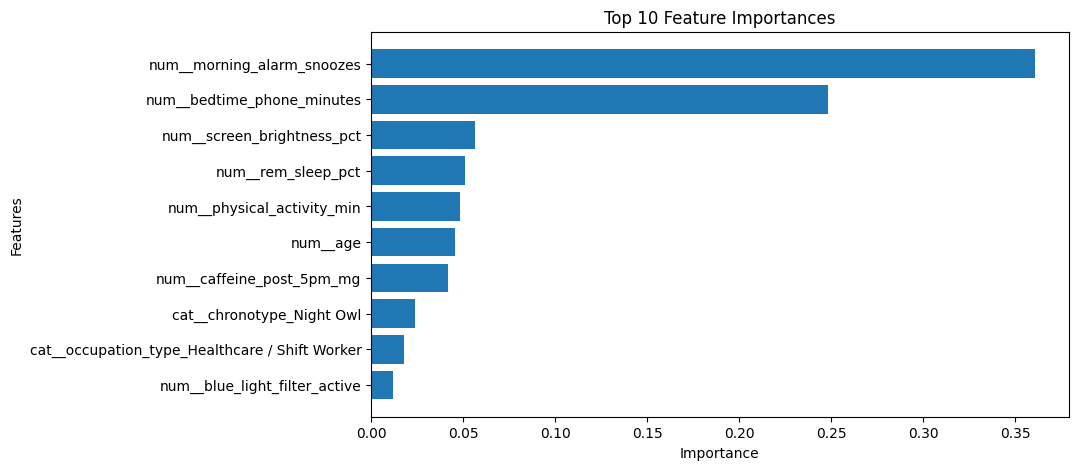

In [17]:
# Get the top 10 important features
top_features = importance_df.tail(10).sort_values(
    by="Importance",
    ascending=False
)

# Plot feature importance
plt.figure(figsize=(9, 5))
plt.barh(top_features["Feature"], top_features["Importance"])

plt.title("Top 10 Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.gca().invert_yaxis()
plt.show()

In [ ]:
# Step 6: Feature Importance

# The three most important features were morning_alarm_snoozes, bedtime_phone_minutes, and screen_brightness_pct.
# Morning alarm snoozes had the highest importance (0.3611), followed by bedtime phone minutes (0.2481).
# The high importance of morning alarm snoozes is worth investigating, but it does not automatically indicate data leakage.
# We also removed gender, occupation_type, and primary_bedtime_app. Recall increased slightly, but F1-score decreased from 0.7476 to 0.7321.
# Therefore, removing these features did not improve the overall model.

In [18]:
# Train the baseline model
rf.fit(X_train, y_train)

# Get baseline predictions
baseline_test_pred = rf.predict(X_test)

# Train the final selected model
final_model = rf

# Get prediction probabilities
test_prob = final_model.predict_proba(X_test)[:, 1]

# Apply the selected threshold
final_test_pred = (test_prob >= 0.4).astype(int)

# Evaluate both models
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Final Model Results")
print("Accuracy:", round(accuracy_score(y_test, final_test_pred), 4))
print("Precision:", round(precision_score(y_test, final_test_pred), 4))
print("Recall:", round(recall_score(y_test, final_test_pred), 4))
print("F1 Score:", round(f1_score(y_test, final_test_pred), 4))

# Check missed severe cases
cm = confusion_matrix(y_test, final_test_pred)

print("Severe cases missed:", cm[1, 0])
print("False alarms:", cm[0, 1])

Final Model Results
Accuracy: 0.97
Precision: 0.8047
Recall: 0.7984
F1 Score: 0.8016
Severe cases missed: 26
False alarms: 25


In [19]:
# Train the model on the complete training data
rf.fit(X_train, y_train)

# Get prediction probabilities
test_prob = rf.predict_proba(X_test)[:, 1]

# Baseline predictions (threshold 0.5)
baseline_pred = (test_prob >= 0.5).astype(int)

# Improved predictions (threshold 0.4)
final_pred = (test_prob >= 0.4).astype(int)

# Create comparison table
comparison = pd.DataFrame([
    {
        "Version": "Baseline RF (0.5)",
        "Accuracy": accuracy_score(y_test, baseline_pred),
        "Precision": precision_score(y_test, baseline_pred),
        "Recall": recall_score(y_test, baseline_pred),
        "F1": f1_score(y_test, baseline_pred)
    },
    {
        "Version": "Improved RF (0.4)",
        "Accuracy": accuracy_score(y_test, final_pred),
        "Precision": precision_score(y_test, final_pred),
        "Recall": recall_score(y_test, final_pred),
        "F1": f1_score(y_test, final_pred)
    }
])

# Display results
display(comparison.round(4))

# Check final model errors
cm = confusion_matrix(y_test, final_pred)

print("False Negatives:", cm[1, 0])
print("False Positives:", cm[0, 1])

,Version,Accuracy,Precision,Recall,F1
0,Baseline RF (0.5),0.9706,0.8835,0.7054,0.7845
1,Improved RF (0.4),0.9700,0.8047,0.7984,0.8016


False Negatives: 26
False Positives: 25


In [ ]:
# Step 7: Final Test and Comparison

# The baseline and improved Random Forest models were evaluated on the test dataset.
# The improved model uses a probability threshold of 0.4, selected through cross-validation on the training data.
# The improved model aims to identify more severe sleep-debt cases, although it may produce more false positives.
# I would prefer the improved model because identifying severe cases is our main priority. However, the trade-off between Recall and Precision should be considered before real-world use.